<a href="https://colab.research.google.com/github/poojagupthaa14/OIBSIP/blob/main/pooja_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [40]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train (1).csv


In [41]:
df = pd.read_csv('train.csv', keep_default_na=False, na_values=[''])

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,2,2008,WD,Normal,208500
1,2,20,RL,80,9600,Pave,NA,Reg,Lvl,AllPub,...,0,NA,NA,NA,0,5,2007,WD,Normal,181500
2,3,60,RL,68,11250,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,9,2008,WD,Normal,223500
3,4,70,RL,60,9550,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84,14260,Pave,NA,IR1,Lvl,AllPub,...,0,NA,NA,NA,0,12,2008,WD,Normal,250000


In [42]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1460, 81)


The Ames Housing dataset is loaded using Pandas. It contains information about different houses, including their area, quality, location and other features. This dataset will be used to analyze house characteristics and build a Linear Regression model to predict selling prices

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Id             1460 non-null   int64 
 1   MSSubClass     1460 non-null   int64 
 2   MSZoning       1460 non-null   object
 3   LotFrontage    1460 non-null   object
 4   LotArea        1460 non-null   int64 
 5   Street         1460 non-null   object
 6   Alley          1460 non-null   object
 7   LotShape       1460 non-null   object
 8   LandContour    1460 non-null   object
 9   Utilities      1460 non-null   object
 10  LotConfig      1460 non-null   object
 11  LandSlope      1460 non-null   object
 12  Neighborhood   1460 non-null   object
 13  Condition1     1460 non-null   object
 14  Condition2     1460 non-null   object
 15  BldgType       1460 non-null   object
 16  HouseStyle     1460 non-null   object
 17  OverallQual    1460 non-null   int64 
 18  OverallCond    1460 non-null

In [44]:
df.describe()

,Id,MSSubClass,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,10516.828082,6.099315,5.575342,1971.267808,1984.865753,443.639726,46.549315,567.240411,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,9981.264932,1.382997,1.112799,30.202904,20.645407,456.098091,161.319273,441.866955,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,223.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,383.500000,0.000000,477.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,712.250000,0.000000,808.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,5644.000000,1474.000000,2336.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### 4.2 Missing Value Analysis

Missing value analysis is performed to identify incomplete data in the dataset. It helps determine which columns contain missing information and how much data is missing. This analysis is important before applying data preprocessing techniques.

In [45]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values.sort_values(ascending=False))

Series([], dtype: int64)


In [46]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_data = missing_data[missing_data['Missing Values'] > 0]

missing_data.sort_values(by='Missing Percentage', ascending=False)

,Missing Values,Missing Percentage


In [47]:
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

Dataset shape: (1460, 81)
Total missing values: 0


## 5. Duplicate Value Analysis

Duplicate records are rows that contain identical information. Identifying and removing duplicates helps maintain data quality and prevents repeated records from affecting our analysis.

In [48]:
# Checking duplicate records

print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


## 6. Target Variable Analysis

SalePrice is the target variable in our dataset. It represents the selling price of each house.

Analyzing its distribution helps us understand the variation in house prices and identify whether the prices are evenly distributed or concentrated within a particular range.

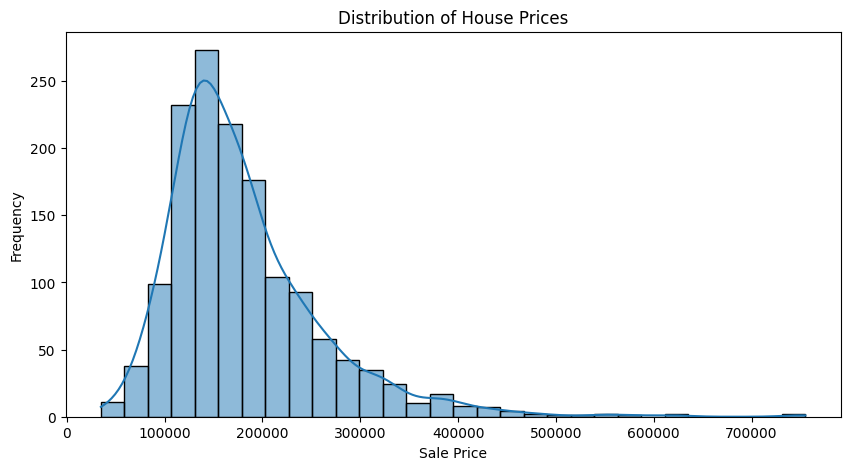

In [49]:
# Visualizing the distribution of house prices

plt.figure(figsize=(10, 5))

sns.histplot(df['SalePrice'], bins=30, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

**Observation:**
- Most houses have selling prices between $100,000 and $200,000.
- The highest concentration of houses is around $150,000.
- The distribution is right-skewed, meaning a small number of houses have very high selling prices.
- Very few houses are priced above $400,000.

**Conclusion:**

Most houses fall within the lower-to-middle price range, while a few expensive houses create a long tail on the right side of the distribution.

## 7. Statistical Analysis of SalePrice

In this section, we calculate statistical measures such as mean, median, minimum, maximum and standard deviation to understand the distribution of house prices.

In [50]:
# Statistical summary of house prices

df['SalePrice'].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


**Observations:**

- The dataset contains 1,460 house records.
- The average selling price (Mean) is approximately $180,921.
- The median selling price is $163,000.
- The minimum house price is $34,900.
- The maximum house price is $755,000.
- The standard deviation is approximately $79,442, indicating considerable variation in house prices.

**Conclusion:**

House prices vary significantly across the dataset. The mean is higher than the median, which supports our earlier observation that the distribution is right-skewed.

## 8. Correlation Analysis

Correlation analysis helps identify the relationship between numerical features and the target variable (SalePrice). It helps us understand which features may be useful for predicting house prices.

In [51]:
# Finding correlation with SalePrice

correlation = df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)

print(correlation.head(10))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


**Observations:**

1. OverallQual has the strongest positive correlation with SalePrice (0.79).
2. GrLivArea has the second-highest correlation (0.71).
3. GarageCars, GarageArea and TotalBsmtSF also show strong positive relationships.
4. Most of the top numerical features have positive correlations with house prices.

**Conclusion:**

OverallQual and GrLivArea appear to be important features for predicting house prices. These features may help our Linear Regression model make better predictions.

## 9. Correlation Heatmap

A correlation heatmap is a graphical representation of relationships between numerical variables. It uses different colors and numerical values to show the strength and direction of correlations.

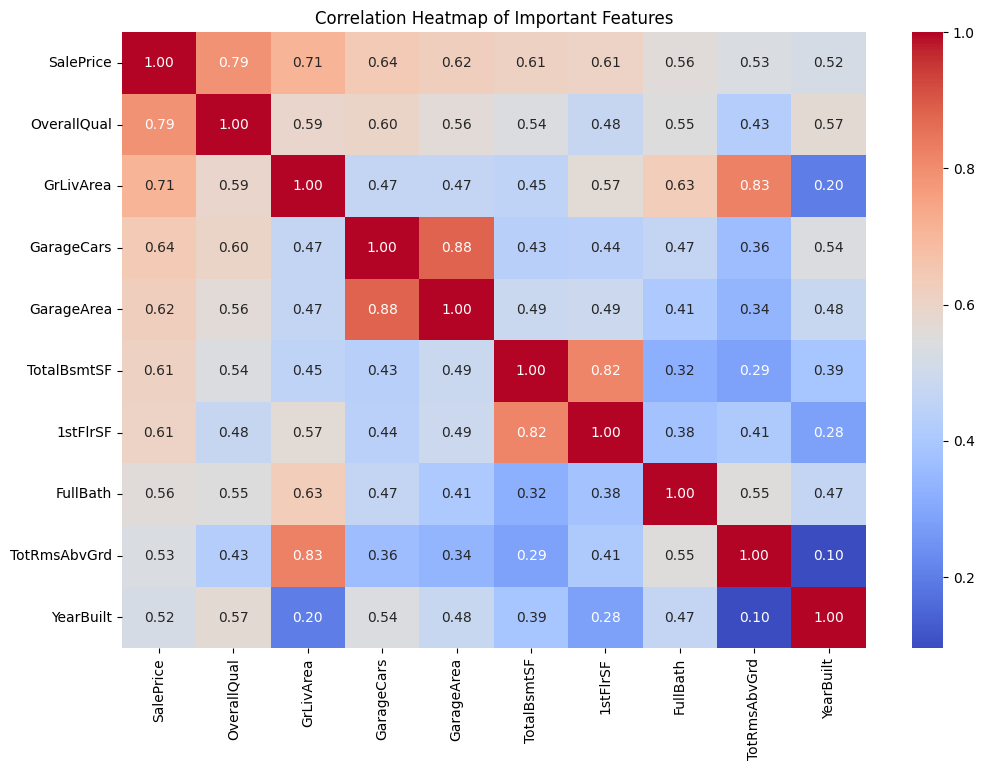

In [52]:
# Selecting important numerical features

top_features = correlation.head(10).index

# Creating correlation matrix

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Important Features')

plt.show()

**Observations:**

1. OverallQual (0.79) has the strongest positive correlation with SalePrice.
2. GrLivArea (0.71) also shows a strong positive relationship with house prices.
3. GarageCars and GarageArea have a high correlation of 0.88 with each other.
4. TotalBsmtSF and 1stFlrSF show a strong correlation of 0.82.
5. Most selected features have positive relationships with SalePrice.

**Conclusion:**

The heatmap indicates that house quality, living area and garage-related features are important factors associated with house prices. These features can be considered during model development.

## 10. Feature Relationship Analysis

In this section, we analyze the relationship between important numerical features and house prices using scatter plots. This helps us understand how individual features are associated with the selling price of houses.

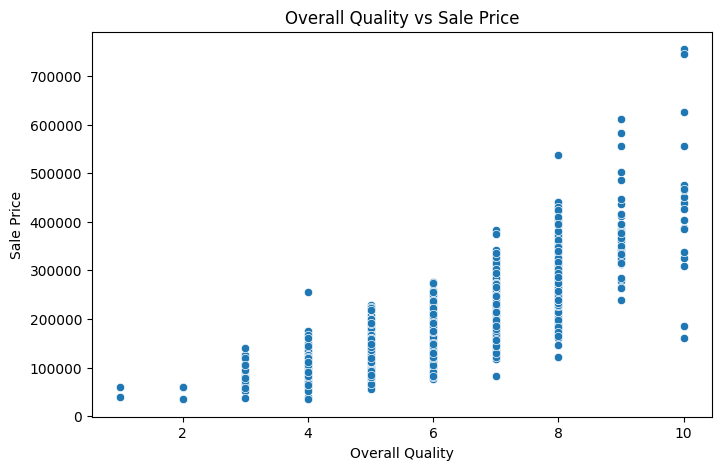

In [53]:
# Relationship between OverallQual and SalePrice

plt.figure(figsize=(8, 5))

sns.scatterplot(x=df['OverallQual'], y=df['SalePrice'])

plt.title('Overall Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

**Observations:**

1. Houses with higher overall quality ratings generally have higher selling prices.
2. Houses with quality ratings between 7 and 10 show higher price ranges.
3. Houses with lower quality ratings generally have lower selling prices.
4. Some high-quality houses have exceptionally high selling prices.

**Conclusion:**

There is a strong positive relationship between overall house quality and selling price. This indicates that OverallQual is an important feature for predicting house prices.

## 11. Living Area vs Sale Price

In this section, we analyze the relationship between the above-ground living area (GrLivArea) and house selling prices. This helps us understand whether larger houses generally have higher selling prices.

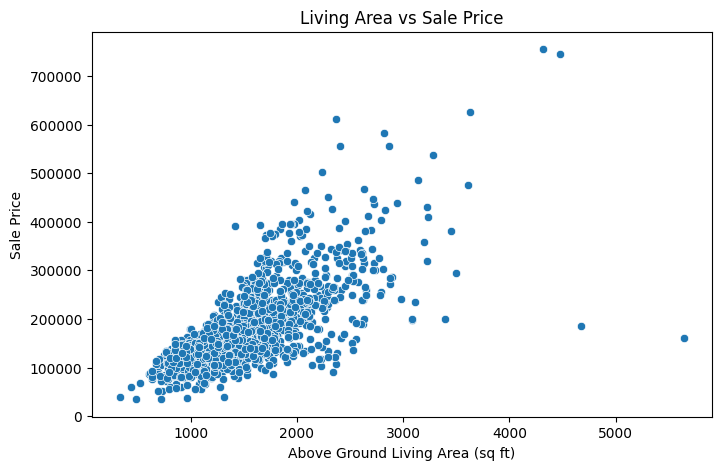

In [54]:
# Relationship between living area and sale price

plt.figure(figsize=(8, 5))

sns.scatterplot(x=df['GrLivArea'], y=df['SalePrice'])

plt.title('Living Area vs Sale Price')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.ylabel('Sale Price')

plt.show()

**Observations:**

1. Houses with larger living areas generally have higher selling prices.
2. Most houses have a living area between 1,000 and 2,500 sq. ft.
3. A positive relationship can be observed between living area and selling price.
4. A few houses have unusually large living areas but relatively low selling prices.
5. Some points are far away from the main group, indicating possible outliers.

**Conclusion:**

Living area has a strong positive relationship with house prices. Generally, larger houses tend to have higher selling prices. Therefore, GrLivArea is an important feature for house price prediction.

## 12. Garage Capacity vs Sale Price

In this section, we analyze the relationship between garage capacity (GarageCars) and house selling prices to understand whether houses with larger garage capacity tend to have higher prices.

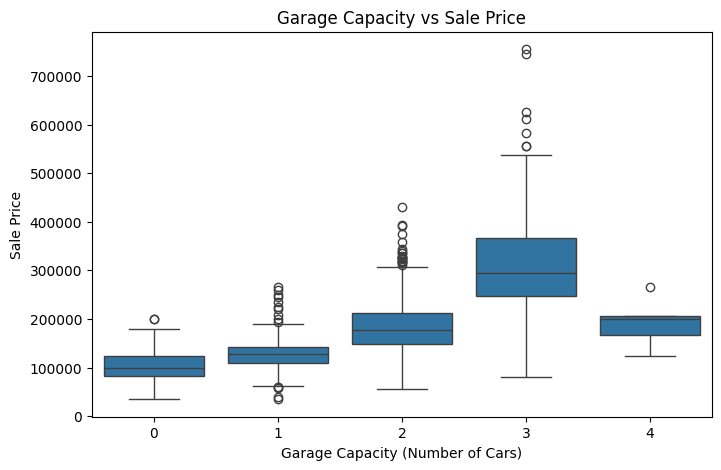

In [55]:
# Relationship between garage capacity and sale price

plt.figure(figsize=(8, 5))

sns.boxplot(x=df['GarageCars'], y=df['SalePrice'])

plt.title('Garage Capacity vs Sale Price')
plt.xlabel('Garage Capacity (Number of Cars)')
plt.ylabel('Sale Price')

plt.show()

**Observations:**

1. Houses with garages that accommodate 3 cars generally have higher selling prices.
2. Houses with no garage or smaller garage capacity generally have lower selling prices.
3. The median selling price increases as garage capacity increases from 0 to 3 cars.
4. Some houses have unusually high selling prices, which appear as outliers.
5. The 4-car garage category contains fewer houses compared to other categories.

**Conclusion:**

Garage capacity has a positive relationship with house prices. Houses with larger garage capacity generally tend to have higher selling prices. Therefore, GarageCars can be a useful feature for house price prediction.

## 13. Data Preparation

Data preparation involves selecting the required features, handling missing values and converting categorical data into numerical format so that the Linear Regression algorithm can process the dataset.

In [56]:
# Separating features and target variable

X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 80)
Target shape: (1460,)


## 14. Identifying Categorical Features

Categorical features contain text-based information. Since Linear Regression works with numerical data, we need to identify these columns and convert them into numerical format before model training.

In [57]:
# Identifying categorical columns

categorical_columns = X.select_dtypes(include=['object']).columns

print("Total categorical columns:", len(categorical_columns))
print("\nCategorical columns:")
print(categorical_columns.tolist())

Total categorical columns: 46

Categorical columns:
['MSZoning', 'LotFrontage', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


## 15. Feature Data Type Verification

Before encoding categorical features, we verify the data types of selected columns. This helps us distinguish numerical features from categorical features and prepare the data correctly.

In [58]:
# Checking data types of selected columns

check_columns = ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']

print(X[check_columns].dtypes)

LotFrontage    object
MasVnrArea     object
GarageYrBlt    object
dtype: object


## 16. Data Type Conversion

Some numerical columns are stored as object data types. We convert them into numerical formats so that they can be properly used during data analysis and model training.

In [59]:
# Checking sample values

for col in ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']:
    print(f"\n{col}:")
    print(X[col].head(10).tolist())


LotFrontage:
['65', '80', '68', '60', '84', '85', '75', 'NA', '51', '50']

MasVnrArea:
['196', '0', '162', '0', '350', '0', '186', '240', '0', '0']

GarageYrBlt:
['2003', '1976', '2001', '1998', '2000', '1993', '2004', '1973', '1931', '1939']


In [60]:
# Converting object columns into numerical data types

for col in ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Checking updated data types

print(X[['LotFrontage', 'MasVnrArea', 'GarageYrBlt']].dtypes)

LotFrontage    float64
MasVnrArea     float64
GarageYrBlt    float64
dtype: object


## 17. Separating Numerical and Categorical Features

In this step, we divide the dataset into numerical and categorical features.

- Numerical features contain measurable values such as area, year and number of rooms.
- Categorical features contain labels or categories such as neighborhood, house style and building type.

This separation helps us apply appropriate preprocessing techniques to each type of feature.

In [61]:
# Separating numerical and categorical features

numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

categorical_features = X.select_dtypes(include=['object']).columns

print("Total numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))

Total numerical features: 37
Total categorical features: 43


## 18. Handling Missing Values

Missing values can affect the performance of a Machine Learning model. In this step, we identify and handle missing values in numerical and categorical features.

- Numerical missing values will be filled using the median.
- Categorical missing values will be filled using the most frequent value (mode).

In [62]:
# Checking missing values in numerical features

print("Missing values in numerical features:")
print(X[numerical_features].isnull().sum().sort_values(ascending=False).head(15))

print("\nMissing values in categorical features:")
print(X[categorical_features].isnull().sum().sort_values(ascending=False).head(15))

Missing values in numerical features:
LotFrontage     259
GarageYrBlt      81
MasVnrArea        8
Id                0
MSSubClass        0
OverallQual       0
LotArea           0
YearBuilt         0
OverallCond       0
BsmtFinSF1        0
BsmtFinSF2        0
BsmtUnfSF         0
YearRemodAdd      0
1stFlrSF          0
2ndFlrSF          0
dtype: int64

Missing values in categorical features:
MSZoning        0
Street          0
Alley           0
LotShape        0
LandContour     0
Utilities       0
LotConfig       0
LandSlope       0
Neighborhood    0
Condition1      0
Condition2      0
BldgType        0
HouseStyle      0
RoofStyle       0
RoofMatl        0
dtype: int64


## 19. Filling Missing Values

In this step, we handle missing values to prepare the dataset for model training.

- Numerical columns are filled using their median values.
- Categorical columns are filled using their most frequent values (mode).

This ensures that the dataset does not contain missing values before applying the Linear Regression algorithm.

In [63]:
# Filling missing values in numerical features

for col in numerical_features:
    X[col] = X[col].fillna(X[col].median())


# Filling missing values in categorical features

for col in categorical_features:
    X[col] = X[col].fillna(X[col].mode()[0])


print("Total missing values:", X.isnull().sum().sum())

Total missing values: 0


## 20. Train-Test Split

In this step, we divide the dataset into training and testing sets.

- 80% of the data is used for training.
- 20% of the data is used for testing.

This helps us evaluate the model's performance on data it has not seen during training.

In [64]:
# Recreating features from the original dataset

X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

# Converting selected columns into numerical format

for col in ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']:
    X[col] = pd.to_numeric(X[col], errors='coerce')

In [65]:
# Splitting data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 80)
Testing data: (292, 80)


## 21. Feature Preprocessing

Feature preprocessing converts raw data into a suitable format for Machine Learning algorithms.

In this step, we remove unnecessary identifier columns and separate numerical and categorical features for further processing.

In [66]:
# Removing unnecessary ID column

X_train = X_train.drop('Id', axis=1)
X_test = X_test.drop('Id', axis=1)

# Separating numerical and categorical features

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X_train.select_dtypes(
    include=['object']
).columns

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 36
Categorical features: 43


## 22. Handling Missing Values and One-Hot Encoding

In this step, we prepare numerical and categorical features using appropriate preprocessing techniques.

- Numerical features: Missing values are filled using the median.
- Categorical features: Missing values are filled using the most frequent value.
- One-Hot Encoding: Categorical values are converted into numerical columns.

These transformations make the dataset suitable for Linear Regression.

In [67]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing

numerical_transformer = SimpleImputer(strategy='median')

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combining both preprocessing techniques

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [68]:
# Fitting preprocessing on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Applying the same preprocessing to testing data

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (1168, 302)
Testing data shape: (292, 302)


## 23. Building the Linear Regression Model

Linear Regression is a supervised Machine Learning algorithm used to predict continuous numerical values.

In this project, we train the model using house features such as quality, living area and garage capacity to predict house selling prices.

In [69]:
# Importing Linear Regression

from sklearn.linear_model import LinearRegression

# Creating the model

model = LinearRegression()

# Training the model

model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


## 24. Making Predictions

After training the Linear Regression model, we use the testing dataset to predict house selling prices.

These predictions will help us understand how well the model performs on unseen data.

In [70]:
# Predicting house prices using testing data

y_pred = model.predict(X_test_processed)

# Displaying actual and predicted prices

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    156122.887428
1        325000    353507.938728
2        115000    103778.650319
3        159000    185312.193436
4        315500    339438.562136
5         75500     60488.643071
6        311500    248592.228751
7        146000    144821.165205
8         84500     60606.795547
9        135500    143307.102033


### 25. Model Evaluation

After making predictions, we need to evaluate how accurately our Linear Regression model predicts house prices.

We use four evaluation metrics:

- **MAE:** Measures the average absolute difference between actual and predicted prices.
- **MSE:** Measures the average squared prediction error.
- **RMSE:** Represents prediction error in the same unit as house prices.
- **R² Score:** Indicates how well the model explains variations in house prices. A score closer to 1 generally indicates a better fit.

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 20595.99771752267
Mean Squared Error (MSE): 971742169.2324721
Root Mean Squared Error (RMSE): 31172.779299133275
R2 Score: 0.8733114938029695


**Observations:**

1. The MAE indicates that the model's predictions differ from actual house prices by approximately $20,596 on average.
2. The RMSE is approximately $31,173, showing the impact of larger prediction errors.
3. The R² score of 0.8733 indicates that the model explains approximately 87.33% of the variation in house prices.
4. Overall, the Linear Regression model demonstrates good predictive performance on the testing dataset.

### 26. Actual vs Predicted Price Visualization

This visualization compares the actual house prices with the prices predicted by the Linear Regression model. It helps us understand how closely the model's predictions match the actual values.

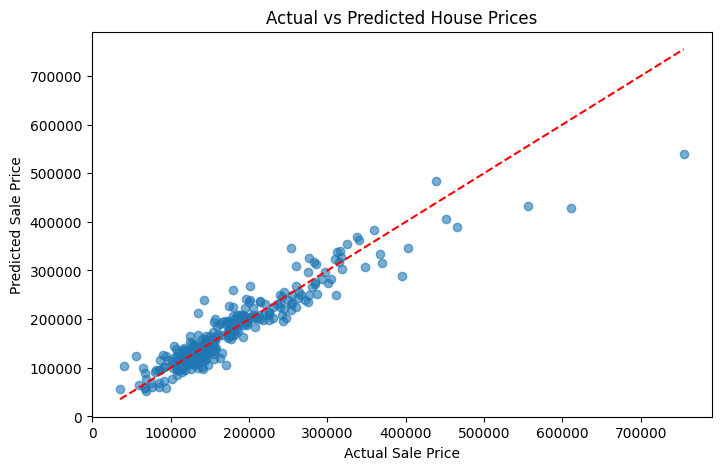

In [72]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price')
plt.title('Actual vs Predicted House Prices')

plt.show()

**Observations:**

1. Most data points are close to the red dashed line, indicating that the model makes reasonably accurate predictions for many houses.
2. Some points are above the line, meaning the model predicted higher prices than the actual prices.
3. Some points are below the line, meaning the model predicted lower prices than the actual prices.
4. The model shows larger prediction differences for some expensive houses.
5. Overall, the visualization indicates that the Linear Regression model performs reasonably well, which is consistent with its R² score of 0.8733.

### 27. Residual Analysis

Residuals are the differences between actual house prices and predicted house prices.

Residual = Actual Price − Predicted Price

Residual analysis helps us understand how far the model's predictions are from the actual values and identify patterns in prediction errors.

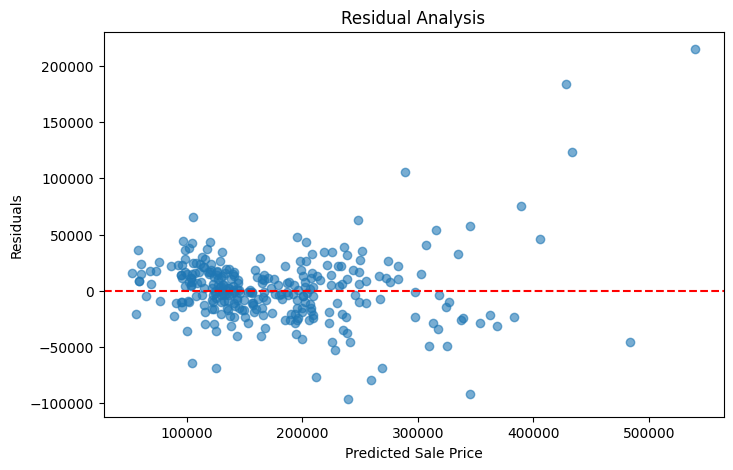

In [73]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Sale Price')
plt.ylabel('Residuals')
plt.title('Residual Analysis')

plt.show()

**Observations:**

1. Most residual values are distributed around the zero line, indicating that the model makes reasonably accurate predictions for many houses.
2. Positive residuals indicate that the model predicted a lower price than the actual price.
3. Negative residuals indicate that the model predicted a higher price than the actual price.
4. Some houses have larger residual values, indicating significant prediction errors.
5. The spread of residuals increases for higher predicted prices, suggesting that the model has more difficulty predicting some expensive houses.

Overall, the residual analysis shows that the model performs reasonably well, but some prediction errors remain.

### 28. Conclusion

In this project, we developed a House Price Prediction model using Linear Regression.

The project involved:
- Loading and understanding the housing dataset.
- Performing data cleaning and exploratory data analysis (EDA).
- Identifying important features affecting house prices.
- Handling missing values and encoding categorical data.
- Splitting the dataset into training and testing sets.
- Training a Linear Regression model.
- Predicting house prices and evaluating model performance.
- Visualizing actual vs predicted prices and analyzing residuals.

**Model Performance:**

- Mean Absolute Error (MAE): 20,595.99
- Root Mean Squared Error (RMSE): 31,172.78
- R² Score: 0.8733 (87.33%)

The model achieved an R² score of 87.33%, indicating good predictive performance on the testing dataset. Overall, this project demonstrates how machine learning can be used to predict house prices based on different property features.